# 04 · Top-k and nucleus

**The question.** How do you get variety without gibberish?

**The claim.** High-temperature gibberish comes from the long tail: many individually unlikely tokens that together hold real probability mass. Top-k and top-p (nucleus) sampling cut that tail before sampling. Top-k keeps a fixed *number* of tokens no matter how confident the model is. Nucleus keeps the smallest set covering a fixed *share* of the probability, so it adapts: one token when the model is sure, hundreds when it is not. That adaptivity is why top-p is the modern default (Holtzman et al., 2020; top-k: Fan et al., 2018).

**By the end** you will know both samplers line by line, when each misbehaves, and that the from-scratch versions match `transformers` bit for bit.

*Outputs:* `outputs/figures/04_*.png` and `outputs/results/04_*.json`.

In [1]:
import inspect
import textwrap

import pandas as pd
import torch

from src.config import get_settings

S = get_settings()
SEED = S.seed
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
print(f"seed = {SEED}  (config/settings.yaml)")

from src.results import save_json
from src.visualisation import save_figure

seed = 42  (config/settings.yaml)


## 1. The tail is where gibberish comes from

Take one distribution from the char model and ask: as temperature rises, how much probability lands *outside* the three most likely characters?

In [2]:
from src.analysis import entropy, top_mass
from src.decoders import apply_temperature
from src.model import default_char_lm, next_token_logits

model = default_char_lm()
prompt = "the sea was "
logits = next_token_logits(model, prompt)
ids = model.encode(prompt)
tail = pd.DataFrame([
    {"temperature": t,
     "mass_outside_top_3": 1 - top_mass(apply_temperature(logits, t), 3).item(),
     "entropy_bits": entropy(apply_temperature(logits, t), base=2).item()}
    for t in [0.5, 1.0, 1.5, 2.0, 3.0]
])
save_json("04_tail_mass", {"prompt": prompt, "by_temperature": tail})
tail.round(3)

,temperature,mass_outside_top_3,entropy_bits
0,0.5,0.000,1.218
1,1.0,0.037,1.790
2,1.5,0.162,2.582
3,2.0,0.313,3.286
4,3.0,0.528,4.072


At T = 1 the tail holds about 4% of the mass; at T = 2 almost a third, and at T = 3 over half. Each step samples from that tail with that probability, and one bad character is enough to derail a word.

## 2. Two samplers, a few lines each

In [3]:
from src.decoders import apply_top_k, apply_top_p

for fn in (apply_top_k, apply_top_p):
    src = inspect.getsource(fn)
    print(src[: src.index('    """')] + src[src.rindex('"""') + 4 :])

def apply_top_k(logits: Tensor, k: int, filter_value: float = NEG_INF) -> Tensor:
    if k <= 0:
        return logits.clone()
    k = min(k, logits.size(-1))
    threshold = torch.topk(logits, k, dim=-1).values[..., -1:]
    return logits.masked_fill(logits < threshold, filter_value)

def apply_top_p(
    logits: Tensor,
    p: float,
    min_tokens_to_keep: int = 1,
    filter_value: float = NEG_INF,
) -> Tensor:
    if not 0.0 < p <= 1.0:
        raise ValueError(f"top_p must be in (0, 1], got {p}")
    if p == 1.0:
        return logits.clone()
    sorted_logits, sorted_idx = torch.sort(logits, dim=-1, descending=True, stable=True)
    sorted_probs = sorted_logits.softmax(dim=-1)
    mass_before = sorted_probs.cumsum(dim=-1) - sorted_probs
    remove_sorted = mass_before >= p
    remove_sorted[..., :min_tokens_to_keep] = False
    remove = remove_sorted.scatter(-1, sorted_idx, remove_sorted)
    return logits.masked_fill(remove, filter_value)



Both mask removed tokens with `-inf` and leave renormalisation to the single softmax that follows. Top-k keeps everything tied with the k-th largest logit. Top-p keeps a token if the mass of the tokens *strictly more probable* than it is still below p, so the token that crosses p is included.

## 3. Cutting the tail of one distribution

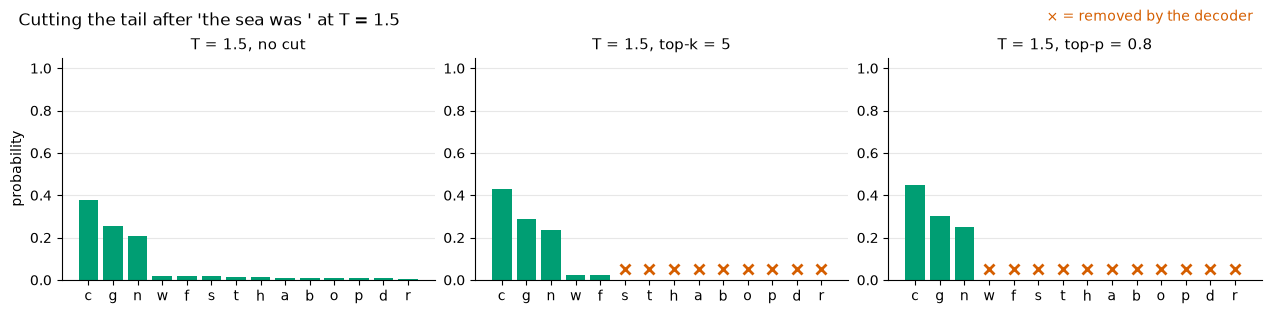

In [4]:
from src.analysis import top_tokens
from src.decoders import Decoder
from src.visualisation import plot_reshaped_distributions

T = 1.5
decoders = {
    "T = 1.5, no cut": Decoder.sampling(T),
    "T = 1.5, top-k = 5": Decoder.top_k_sampling(5, T),
    "T = 1.5, top-p = 0.8": Decoder.nucleus(0.8, T),
}
warped = {name: d.warp(logits, ids) for name, d in decoders.items()}
fig = plot_reshaped_distributions(model, logits, warped, n=14,
                                  title=f"Cutting the tail after {prompt!r} at T = {T:g}")
save_figure(fig, "04_cutting_the_tail")
shown = top_tokens(model, logits, n=14)
save_json("04_cutting_the_tail", {
    "prompt": prompt, "temperature": T, "tokens": shown["token"],
    "probabilities": {
        name: dict(zip(shown["token"], torch.softmax(w, dim=-1)[0, shown["token_id"]].tolist()))
        for name, w in warped.items()
    },
    "tokens_kept": {name: int(torch.isfinite(w).sum()) for name, w in warped.items()},
});

Here the nucleus keeps three characters and top-k keeps five: on this distribution `k = 5` is generous, so two of its survivors are tail characters the nucleus removes.

## 4. Variety without gibberish, measured

Same open-ended prompts, five samples each, two metrics: **real-word rate** (fluent) and **distinct-2** (varied).

,open_valid_words,open_distinct_2,open_diversity,open_score
decoder,,,,
T=1.5,0.58,0.96,0.89,0.56
"T=1.5, top-k=5",0.71,0.95,0.86,0.67
"T=1.5, top-p=0.8",0.95,0.88,0.68,0.84
"T=2, top-p=0.8",0.60,0.97,0.89,0.58
"T=1, top-p=0.8",0.99,0.86,0.66,0.85


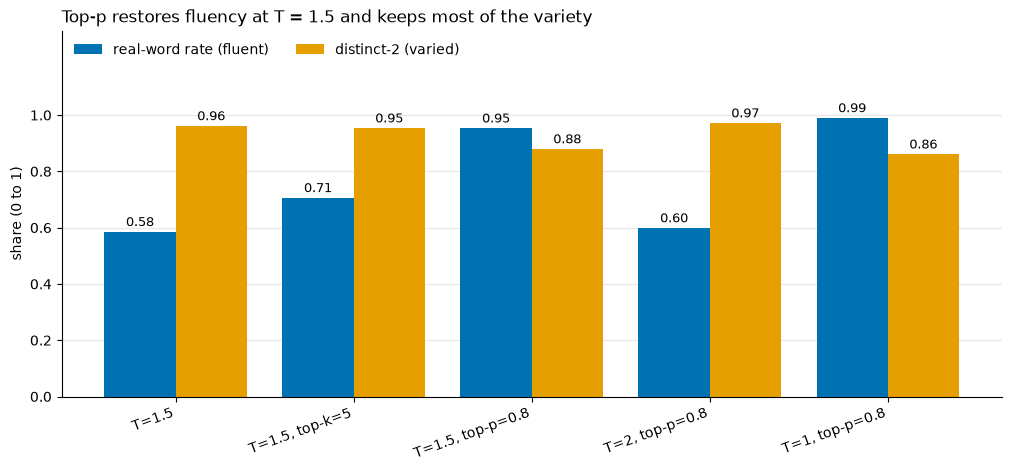

In [5]:
from src.datasets import char_prompts
from src.evaluation import corpus_lexicon, run_arena, summarize_arena
from src.visualisation import plot_grouped_bars

strategies = [
    Decoder.sampling(1.5),
    Decoder.top_k_sampling(5, 1.5),
    Decoder.nucleus(0.8, 1.5),
    Decoder.nucleus(0.8, 2.0),
    Decoder.nucleus(0.8, 1.0),
]
arena = run_arena(model, char_prompts("open"), strategies, n_samples=S.generation.n_samples,
                  max_new_tokens=S.generation.max_new_tokens, seed=SEED,
                  lexicon=corpus_lexicon(), score_quality=False)
summary = summarize_arena(arena, S.generation.n_samples)
cols = {"open_valid_words": "real-word rate (fluent)", "open_distinct_2": "distinct-2 (varied)"}
fig = plot_grouped_bars(summary, cols, ylabel="share (0 to 1)",
                        title="Top-p restores fluency at T = 1.5 and keeps most of the variety")
save_figure(fig, "04_tail_cut_fluency")
save_json("04_tail_cut_fluency", {
    "n_samples": S.generation.n_samples, "max_new_tokens": S.generation.max_new_tokens,
    "summary": summary[[*cols, "open_diversity", "open_score"]],
    "samples": arena[["prompt", "decoder", "sample", "completion"]],
})
summary[[*cols, "open_diversity", "open_score"]].round(2)

At T = 1.5 with no cut, barely half the words are real. Top-k = 5 helps a little. Top-p = 0.8 brings the real-word rate back to about 0.95 while distinct-2 stays high (0.96 → 0.88). Some variety is lost, but much of what is lost was the "variety" of nonsense: random letter strings never repeat, so gibberish always scores well on distinct-n. That is why fluency has to be read next to it.

The T = 2 row is a warning about *order*. Temperature runs before top-p, so at T = 2 the distribution is already flat when the nucleus is computed, and a flat distribution needs many tokens to reach p. The cut is still there; it just keeps more.

## 5. Where a fixed k goes wrong

The same k means very different things on a peaked and a flat distribution. Three contexts from the char model:

peaked ('the capital of fra')    entropy 0.23 bits, top-1 p = 0.98
medium ('the sea was ')          entropy 1.79 bits, top-1 p = 0.49
flat ('and the ')                entropy 3.21 bits, top-1 p = 0.20


distribution    flat ('and the ')  medium ('the sea was ')  peaked ('the capital of fra')
method setting                                                                           
top-k  1.00                 0.204                    0.490                          0.977
       3.00                 0.502                    0.963                          0.987
       5.00                 0.712                    0.976                          0.992
       10.00                0.992                    0.991                          0.998
       20.00                1.000                    1.000                          1.000
top-p  0.50                 0.502                    0.760                          0.977
       0.70                 0.712                    0.760                          0.977
       0.80                 0.833                    0.963                          0.977
       0.90                 0.943                    0.963                          0.977
       0.95                 0.992                    0.963                          0.977
       0.99                 0.992                    0.991                          0.992

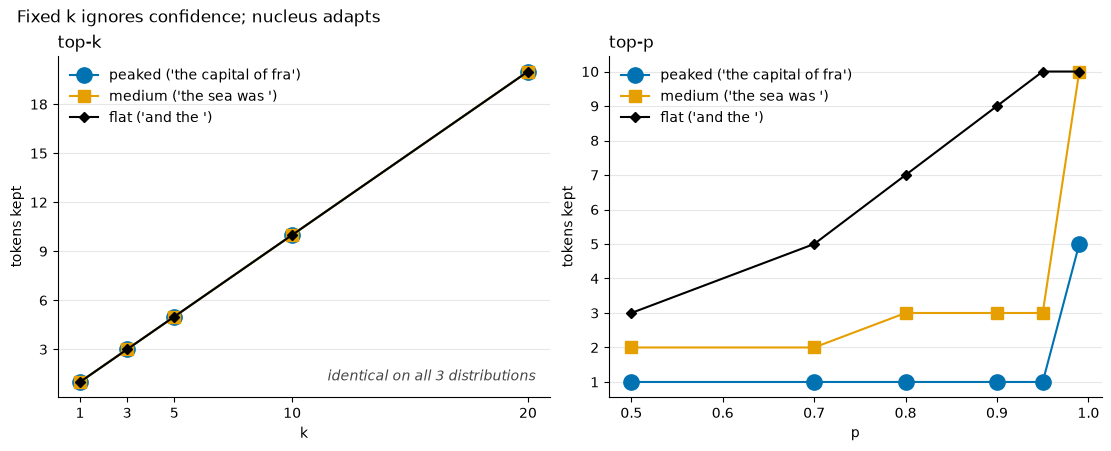

In [6]:
from src.analysis import kept_set_sizes
from src.visualisation import plot_kept_set_sizes

contexts = {
    "peaked ('the capital of fra')": next_token_logits(model, "the capital of fra"),
    "medium ('the sea was ')": logits,
    "flat ('and the ')": next_token_logits(model, "and the "),
}
for name, z in contexts.items():
    print(f"{name:32s} entropy {entropy(z, base=2).item():.2f} bits, "
          f"top-1 p = {torch.softmax(z, dim=-1).max().item():.2f}")
kept = kept_set_sizes(contexts, ks=S.decoding.top_k_values, ps=S.decoding.top_p_values)
fig = plot_kept_set_sizes(kept)
save_figure(fig, "04_fixed_k_vs_nucleus")
save_json("04_fixed_k_vs_nucleus", {
    "entropy_bits": {n: entropy(z, base=2).item() for n, z in contexts.items()},
    "kept": kept,
})
kept.pivot_table(index=["method", "setting"], columns="distribution", values="mass_kept").round(3)

Read the left panel: top-k keeps exactly k tokens on all three distributions. On the peaked one, where a single character holds 98% of the mass, `k = 5` keeps four characters that are almost certainly wrong. Read the right panel: the nucleus keeps a single token on the peaked distribution for every p up to 0.95, and up to ten on the flat one. The table shows the other side: on the flat distribution a small k throws away plausible mass that the nucleus keeps.

## 6. The same effect at real scale

In [7]:
from huggingface_hub.utils import logging as hub_logging
from transformers.utils import logging as hf_logging

from src.model import load_model

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error()
hf = load_model("hf")  # distilgpt2: ~350 MB on first use, cached afterwards

In [8]:
real = []
for p in ["The United States of", "Thank you very", "My favourite thing is", "I like"]:
    z = next_token_logits(hf, p)
    real.append({
        "prompt": p,
        "entropy_bits": entropy(z, base=2).item(),
        "top1_prob": torch.softmax(z, dim=-1).max().item(),
        "top_p_0.9_keeps": int(torch.isfinite(apply_top_p(z, 0.9)).sum()),
        "top_k_50_keeps": int(torch.isfinite(apply_top_k(z, 50)).sum()),
        "mass_in_top_50": top_mass(z, 50).item(),
    })
real = pd.DataFrame(real)
save_json("04_distilgpt2_peaked_vs_flat", {"model": hf.name, "vocab_size": hf.vocab_size, "rows": real})
real.round(3)

,prompt,entropy_bits,top1_prob,top_p_0.9_keeps,top_k_50_keeps,mass_in_top_50
0,The United States of,0.426,0.972,1,50,0.988
1,Thank you very,2.109,0.766,7,50,0.958
2,My favourite thing is,4.860,0.293,120,50,0.863
3,I like,6.997,0.289,1730,50,0.709


After "The United States of" the nucleus keeps a single token; after "I like" it keeps well over a thousand. A fixed `k = 50` keeps 49 junk candidates in the first case and discards almost a third of the probability in the second.

## 7. Validated against `transformers`

The from-scratch warpers against `TemperatureLogitsWarper`, `TopKLogitsWarper`, `TopPLogitsWarper` and `RepetitionPenaltyLogitsProcessor`, on a char-model distribution and a real `distilgpt2` one. `identical` means bit-for-bit equal, `-inf` entries included.

In [9]:
from src.evaluation import compare_warpers

checks = pd.concat([
    compare_warpers(logits, ids).assign(model=model.name),
    compare_warpers(next_token_logits(hf, "I like"), hf.encode("I like")).assign(model=hf.name),
], ignore_index=True)
assert checks["identical"].all()
save_json("04_vs_transformers", checks)
checks[["model", "case", "kept_ours", "kept_transformers", "identical"]]

,model,case,kept_ours,kept_transformers,identical
0,char-lm,temperature=0.7,29,29,True
1,char-lm,temperature=1.8,29,29,True
2,char-lm,top_k=5,5,5,True
3,char-lm,top_k=50,29,29,True
4,char-lm,top_p=0.5,2,2,True
5,char-lm,top_p=0.9,3,3,True
6,char-lm,repetition_penalty=1.3,29,29,True
7,char-lm,"temperature=0.8, top_k=40, top_p=0.95, repetition_penalty=1.2",3,3,True
8,distilgpt2,temperature=0.7,50257,50257,True
9,distilgpt2,temperature=1.8,50257,50257,True


## What this bought you

- Gibberish at high temperature is the long tail being sampled. Cutting the tail removes it without removing the variety.
- Top-k keeps a fixed number of tokens: too many when the model is sure, too few when it is not.
- Top-p keeps a fixed share of the probability, so the number of tokens adapts to the model's confidence. That is why it is the default.
- Order matters: temperature is applied before the nucleus is computed, so very high temperature still widens the nucleus.
- Both match `transformers` exactly (also asserted in `tests/test_vs_reference.py`).

Next: [05 · Beam search](05_beam_search.ipynb), which drops randomness entirely and searches for the most probable whole sequence.